# Exercise 3: Inference on the Alveo U55C and Comparison with the CPU

## Objectives
In this exercise, you will:
1. Load the bitstream on the Alveo U55C
2. Run the hybrid model: the encoder on the CPU, the pair building and the pair classifier on the FPGA
3. Check the results against the C simulation, the float model and the track reconstruction
4. Measure the time per event, and compare it with the CPU
5. Find where the time goes, and make the hybrid faster with batching

## Instructions
Complete the code cells marked with `# TODO` comments. Follow the hints provided.

## Part 1: Environment Setup
Run the following cells to set up the environment (no changes needed). <br>
This exercise needs XRT and the card: start Jupyter after `HI_CONDA_ENV=hybrid-tutorial source env.sh xrt`. It uses the files written by Exercises 1 and 2 in `work/`.

**Important:** the card is shared. The first cell checks that nobody is using it; loading the bitstream replaces whatever the card had.

In [1]:
# Load libraries and import packages (no changes needed)

# General imports
import sys
import json
import time
from pathlib import Path

# Numpy and plotting
import numpy as np
import matplotlib.pyplot as plt

# ONNX Runtime, to run the encoder (and the full model, for the comparison)
import onnxruntime

# Project folders: the project is the folder with hi_common.py, this exercise is in its school/ folder
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "hi_common.py").exists():
        PROJECT_DIR = folder
        break
SCHOOL_DIR = PROJECT_DIR / "school"
sys.path.insert(0, str(PROJECT_DIR))
sys.path.insert(0, str(SCHOOL_DIR))

# Helpers of the project: configuration, events, edges, tracks, and the drivers of the kernel
import hi_common
from hybrid import cluster_event, tracks_from_edges
from pairhead_backends import PairEdgesFPGA, PairEdgesCSim

# Local file with some useful methods (plots, helpers)
from utils import *

# Configuration and files
CONFIG = hi_common.load_config(PROJECT_DIR / "config" / "hybrid_small_data.yaml")
FULL_MODEL = PROJECT_DIR / "artifacts" / "ckpt-e7c02308" / "onnx" / "full_current.onnx"   # the trained model
WORK_DIR = SCHOOL_DIR / "work"
FIGURE_DIR = WORK_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
THRESHOLD = CONFIG["operating_threshold"]       # a pair is an edge when p1 is above it - DO NOT CHANGE
CARD_ADDRESS = CONFIG["fpga"]["device"]         # PCIe address of the Alveo U55C        - DO NOT CHANGE

BITSTREAM = json.loads((WORK_DIR / "fpga" / "pairedges.json").read_text())     # written by Exercise 2
BITSTREAM_FILE = WORK_DIR / "fpga" / BITSTREAM["xclbin"]
FRACTION_BITS = BITSTREAM["frac_bits"]                                         # integer logit = logit x 2^FRACTION_BITS
CANDIDATE_THRESHOLD = hi_common.candidate_thr_raw(THRESHOLD, FRACTION_BITS)    # the kernel's test on l1 - l0

use_course_style()
print(f"Bitstream: {BITSTREAM_FILE.relative_to(SCHOOL_DIR)}, kernel clock {BITSTREAM['kernel_mhz']:.0f} MHz, "
      f"precision of the pair classifier w12_d14")
check_card_is_free(CARD_ADDRESS)
print("Environment setup correctly!")

Bitstream: work/fpga/prebuilt/pairedges.xclbin, kernel clock 300 MHz, precision of the pair classifier w12_d14


Xclbin UUID: 6D41F854-148C-7387-0C9B-1DC94C27A1BA
0      pairedges:pairedges_1  0xc00000      0      (IDLE)
The card is free
Environment setup correctly!


## Part 2: The Hybrid Model
We run the model in three ways, and all of them end with the same output, the **edges**: the pairs with p₁ above the threshold, with their p₁. The edges are all the track reconstruction needs.
- **full**: the trained model, all on the CPU with ONNX Runtime
- **split**: the two parts of Exercise 1 on the CPU: `encoder.onnx`, the pairs built with numpy, `pair_head.onnx`
- **card**: the **hybrid** model: `encoder.onnx` on the CPU, then one call to the card. The driver copies the embeddings to the card memory, starts the kernel and waits for it, and reads back the candidates (the pairs that can pass the threshold, with their logits). The CPU then applies the softmax and the threshold to the candidates only.

The cell below loads the 400 test events. They are first clustered, as the tracking code does, and we keep what the track reconstruction needs.

In [2]:
# Load the test events, and the two CPU models (no changes needed)
model_config, _ = hi_common.model_config(CONFIG)
tracking = hi_common.import_metrics(CONFIG)          # the clustering and track-building functions of the repo

events = []
for event in hi_common.load_events(CONFIG, model_config, CONFIG["data"]["eval_split"]):
    clustered_dataframe, clustered_hits, cluster_of_hit = cluster_event(tracking, event["df"], event["features"])
    if len(clustered_hits) > 0:
        events.append({"name": event["name"], "hits": clustered_hits, "dataframe": event["df"],
                       "clustered_dataframe": clustered_dataframe, "cluster_of_hit": cluster_of_hit})
hits_per_event = np.array([len(event["hits"]) for event in events])
pairs_per_event = hits_per_event * (hits_per_event + 1) // 2
print(f"{len(events)} events, median {np.median(hits_per_event):.0f} hits (at most {hits_per_event.max()}), "
      f"{int(pairs_per_event.sum()):,} pairs")


def ort_session(model_path, n_threads=1):
    options = onnxruntime.SessionOptions()
    options.intra_op_num_threads = n_threads
    options.inter_op_num_threads = 1
    options.execution_mode = onnxruntime.ExecutionMode.ORT_SEQUENTIAL
    options.graph_optimization_level = onnxruntime.GraphOptimizationLevel.ORT_ENABLE_ALL   # all the optimisations
    return onnxruntime.InferenceSession(str(model_path), options, providers=["CPUExecutionProvider"])


full_session = ort_session(FULL_MODEL)
encoder_session = ort_session(WORK_DIR / "onnx" / "encoder.onnx")
pair_head_session = ort_session(WORK_DIR / "onnx" / "pair_head.onnx")

400 events, median 51 hits (at most 136), 627,350 pairs


### Task 2.1: Open the Card
`PairEdgesFPGA` is the driver of the kernel (Python on top of a small C++ library that uses XRT, the Xilinx runtime). Creating it **loads the bitstream on the card**.

In [3]:
# SOLUTION: open the card: load the bitstream, with the settings written by Exercise 2

card = PairEdgesFPGA(BITSTREAM_FILE, d=BITSTREAM["d"], device=CARD_ADDRESS, kernel=BITSTREAM["kernel"], mode=1)

kernel_simulation = PairEdgesCSim(BITSTREAM["kernel_dir"])     # the same kernel in C simulation (Exercise 2)
print_dict(card.info)

kernel: pairedges
mode: 1
group_id: 0
offsets: [16, 28, 40, 48, 56, 68]
max_hits: 65536
max_events: 1024
max_cand: 8388608


The cell below defines the two CPU paths. Each path takes the hits of one event and a dictionary where it writes the time of each of its stages, and returns the edges. The CPU paths get every reasonable help: the pair list depends only on the number of hits, so it is computed once per size and kept; the pairs are built in one numpy operation; ONNX Runtime applies all its optimisations.

In [4]:
# The two CPU paths (no changes needed)
pair_lists = {}            # the pair list of each event size, computed once


def pair_list(n_hits):
    if n_hits not in pair_lists:
        rows, columns = np.triu_indices(n_hits)
        pair_lists[n_hits] = np.ascontiguousarray(np.stack([rows, columns], axis=1).astype(np.int64))
    return pair_lists[n_hits]


def microseconds(start_ns, end_ns):
    return (end_ns - start_ns) / 1e3


def encode(hits):
    return encoder_session.run(None, {"data": hits})[0][0]        # the embeddings [N, 32]


def run_full(hits, times):
    start = time.perf_counter_ns()
    probabilities = full_session.run(None, {"data": hits, "pair_indices": pair_list(len(hits))})[0]
    after_model = time.perf_counter_ns()
    edges = hi_common.edges_from_probs(probabilities[0, :, 1], THRESHOLD)       # (pair rows, p1) above the threshold
    after_edges = time.perf_counter_ns()
    times["model"] = microseconds(start, after_model)
    times["edges"] = microseconds(after_model, after_edges)
    return edges


def run_split(hits, times):
    start = time.perf_counter_ns()
    embeddings = encode(hits)
    after_encoder = time.perf_counter_ns()
    pairs = pair_list(len(hits))
    pair_features = embeddings[pairs].reshape(len(pairs), -1)     # [e_i, e_j] for every pair, in one operation
    after_pairs = time.perf_counter_ns()
    logits = pair_head_session.run(None, {"pair_features": pair_features})[0]
    after_head = time.perf_counter_ns()
    edges = hi_common.edges_from_logits(logits, THRESHOLD)
    after_edges = time.perf_counter_ns()
    times["encoder"] = microseconds(start, after_encoder)
    times["pairs"] = microseconds(after_encoder, after_pairs)
    times["head"] = microseconds(after_pairs, after_head)
    times["edges"] = microseconds(after_head, after_edges)
    return edges

### Task 2.2: The Hybrid Path
Now write the hybrid path, in the same style: the encoder on the CPU, one call to the card, and the edges from the candidates.

In [5]:
# SOLUTION: write the hybrid path: encoder on the CPU, one card call, the edges from the candidates

def run_card(hits, times):
    start = time.perf_counter_ns()
    embeddings = encode(hits)
    after_encoder = time.perf_counter_ns()
    rows, logit0, logit1, _ = card.run_unpacked([embeddings], CANDIDATE_THRESHOLD, FRACTION_BITS)
    after_card = time.perf_counter_ns()
    edges = hi_common.edges_from_unpacked(rows, logit0, logit1, THRESHOLD)
    after_edges = time.perf_counter_ns()
    times["encoder"] = microseconds(start, after_encoder)
    times["card"] = microseconds(after_encoder, after_card)
    times["edges"] = microseconds(after_card, after_edges)
    for part, value in card.timing.items():          # the driver's own timers: copies, transfers, kernel
        times[f"card_{part}"] = value
    return edges

PATHS = {"full": run_full, "split": run_split, "card": run_card}

first_event = events[0]["hits"]
card_rows, card_p1 = run_card(first_event, {})
print(f"First event: {len(first_event)} hits, {len(pair_list(len(first_event)))} pairs -> {len(card_rows)} edges from the card")

First event: 72 hits, 2628 pairs -> 731 edges from the card


## Part 3: Correctness
Three checks, from the hardware outwards:
1. **card vs C simulation**: the card must return exactly the candidates of the kernel's C simulation, which Exercise 2 checked against the _hls4ml_ model
2. **edges vs the float model**: the fixed-point pair classifier moves p₁ by up to about 10⁻³, so a few pairs right at the threshold can change side
3. **tracks**: the track reconstruction of the repo on the edges of each path, against the true tracks

### Task 3.1: The Card vs the C Simulation

In [6]:
# SOLUTION: check, on every event, that the card returns exactly the candidates of the C simulation

bit_exact = True

for event in events:
    embeddings = encode(event["hits"])
    card_words = card.run([embeddings], CANDIDATE_THRESHOLD)[0][0]
    simulation_words = kernel_simulation.run([embeddings], CANDIDATE_THRESHOLD)[0][0]
    bit_exact = bit_exact and np.array_equal(card_words, simulation_words)

print(f"Card == C simulation, bit for bit, on all the {len(events)} events: {bit_exact}")

Card == C simulation, bit for bit, on all the 400 events: True


The cell below runs the three paths on all the events, compares their edges with those of the full model, and reconstructs the tracks from the edges of each path.

split: 0 of the 165,986 edges differ from the full model; largest p1 difference on the common edges 8.9e-08
card : 174 of the 165,986 edges differ from the full model; largest p1 difference on the common edges 1.5e-03


Tracks of full : 3,955 true positives, 421 false positives, 874 missed


Tracks of split: 3,955 true positives, 421 false positives, 874 missed


Tracks of card : 3,954 true positives, 422 false positives, 875 missed


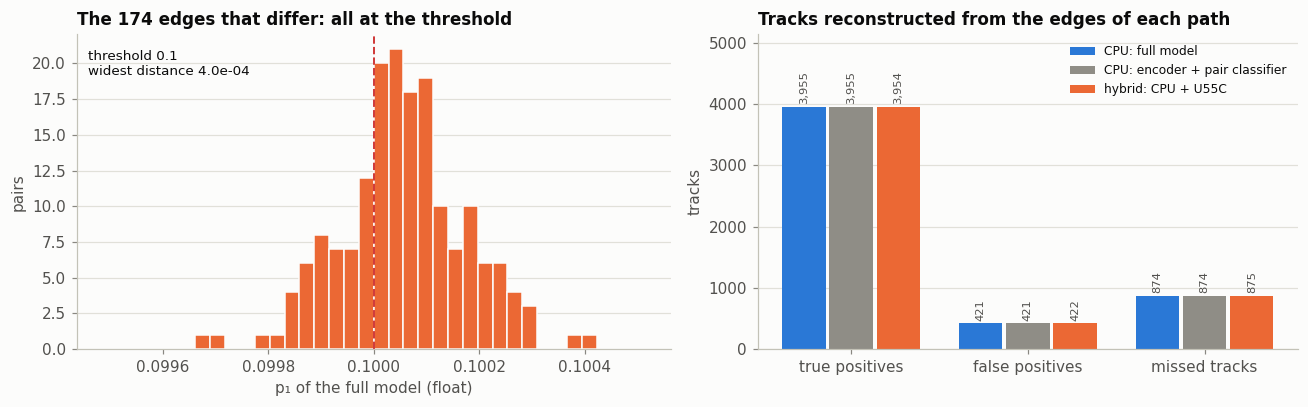

Plot saved as 'work/figures/agreement.png'


In [7]:
# Edges and tracks of the three paths (no changes needed)
edges_of_path = {path: [run(event["hits"], {}) for event in events] for path, run in PATHS.items()}


def compare_edges(edges_a, edges_b):
    # the number of edges found by only one of the two, and the largest p1 difference on the edges both found
    n_differing, max_p1_difference = 0, 0.0
    for (rows_a, p1_a), (rows_b, p1_b) in zip(edges_a, edges_b):
        n_differing += len(set(rows_a.tolist()) ^ set(rows_b.tolist()))
        common_rows, index_a, index_b = np.intersect1d(rows_a, rows_b, return_indices=True)
        if len(common_rows) > 0:
            max_p1_difference = max(max_p1_difference, float(np.abs(p1_a[index_a] - p1_b[index_b]).max()))
    return n_differing, max_p1_difference


n_edges = sum(len(rows) for rows, _ in edges_of_path["full"])
for path in ("split", "card"):
    n_differing, max_p1_difference = compare_edges(edges_of_path[path], edges_of_path["full"])
    print(f"{path:5s}: {n_differing} of the {n_edges:,} edges differ from the full model; "
          f"largest p1 difference on the common edges {max_p1_difference:.1e}")

# the full model's p1 of the pairs that are an edge for the card or for the full model, but not for both
differing_p1 = []
for event, (card_rows, _), (full_rows, _) in zip(events, edges_of_path["card"], edges_of_path["full"]):
    differing_rows = np.array(sorted(set(card_rows.tolist()) ^ set(full_rows.tolist())), dtype=np.int64)
    if len(differing_rows):
        full_p1 = full_session.run(None, {"data": event["hits"], "pair_indices": pair_list(len(event["hits"]))})[0][0, :, 1]
        differing_p1.extend(full_p1[differing_rows])
differing_p1 = np.array(differing_p1)

tracks = {}
for path, edges_per_event in edges_of_path.items():
    totals = np.zeros(3, dtype=int)
    for edges, event in zip(edges_per_event, events):
        result = tracks_from_edges(tracking, pair_list(len(event["hits"])), edges, event["clustered_dataframe"],
                                   event["cluster_of_hit"], event["dataframe"])
        totals += [result["tp"], result["fp"], result["fn"]]
    tracks[path] = totals.tolist()
    print(f"Tracks of {path:5s}: {totals[0]:,} true positives, {totals[1]:,} false positives, {totals[2]:,} missed")

plot_agreement(differing_p1, THRESHOLD, tracks, save_to=FIGURE_DIR / "agreement.png")
print("Plot saved as 'work/figures/agreement.png'")

The card is bit-exact with the C simulation, so it computes exactly the fixed-point model of Exercise 2. The few edges that differ from the float model are all pairs whose p₁ sits right at the threshold (a few 10⁻⁴ from it at most, see the plot), where the fixed-point rounding can push them to the other side; and the tracks agree with those of the float model to within one or two.

## Part 4: The Time per Event
`measure` runs each event several times (after some warm-up events, so that caches and the card are ready) and keeps, for every event, the median time of each stage and of the whole path.

In [8]:
# Time the stages of a path on every event (no changes needed)
def measure(run, events, repeats=5, warmup=20):
    for event in events[:warmup]:
        run(event["hits"], {})
    per_event = []
    for event in events:
        runs = []
        for _ in range(repeats):
            times = {}
            start = time.perf_counter_ns()
            run(event["hits"], times)
            times["total"] = microseconds(start, time.perf_counter_ns())
            runs.append(times)
        per_event.append({stage: float(np.median([times[stage] for times in runs])) for stage in runs[0]})
    return per_event

### Task 4.1: Measure the Three Paths

In [9]:
# SOLUTION: measure the three paths on all the events, and keep the total time of every event

timings = {}    # path -> [{stage: µs} for every event]
total_us = {}   # path -> np.array of the total µs of every event

for path, run in PATHS.items():
    timings[path] = measure(run, events)
    total_us[path] = np.array([times["total"] for times in timings[path]])

full_median = np.median(total_us["full"])
print(f"{'path':32s} {'median':>9s} {'mean':>9s} {'events/s':>9s} {'vs full':>8s}")
for path in PATHS:
    times = total_us[path]
    print(f"{PATH_LABEL[path]:32s} {np.median(times):7.1f}µs {times.mean():7.1f}µs {1e6 / times.mean():9,.0f} "
          f"{full_median / np.median(times):7.2f}×")

path                                median      mean  events/s  vs full
CPU: full model                    357.1µs   407.8µs     2,452    1.00×
CPU: encoder + pair classifier     373.7µs   430.9µs     2,321    0.96×
hybrid: CPU + U55C                 195.4µs   204.3µs     4,896    1.83×


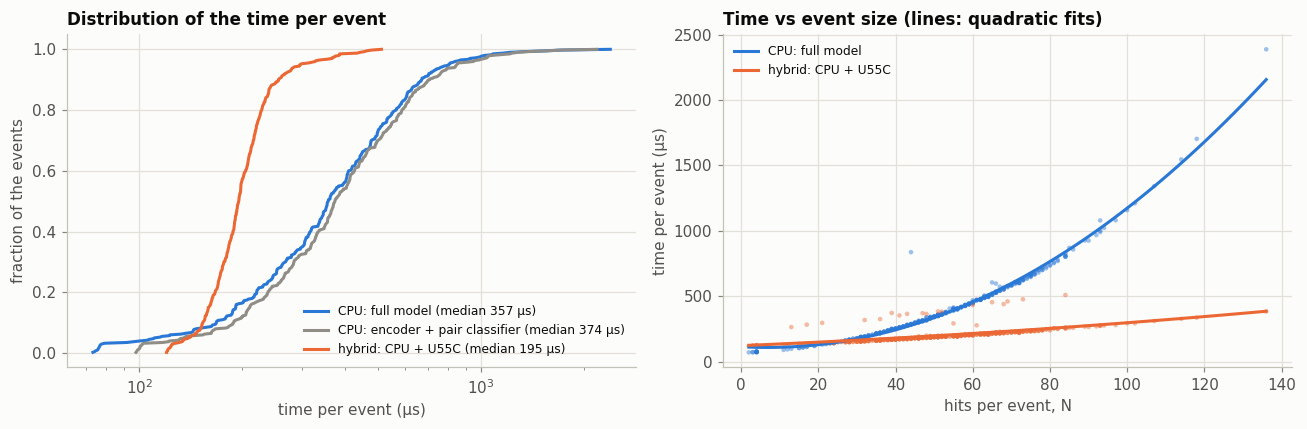

Plot saved as 'work/figures/latency.png'


In [10]:
# Visualize the time per event (no changes needed)
plot_latency(total_us, hits_per_event, save_to=FIGURE_DIR / "latency.png")
print("Plot saved as 'work/figures/latency.png'")

The hybrid is faster than the full model on the CPU, and the gap grows with the size of the event: the CPU's work on the pairs grows like *N²*, while the card handles one pair per clock.

### Task 4.2: Where the Time Goes

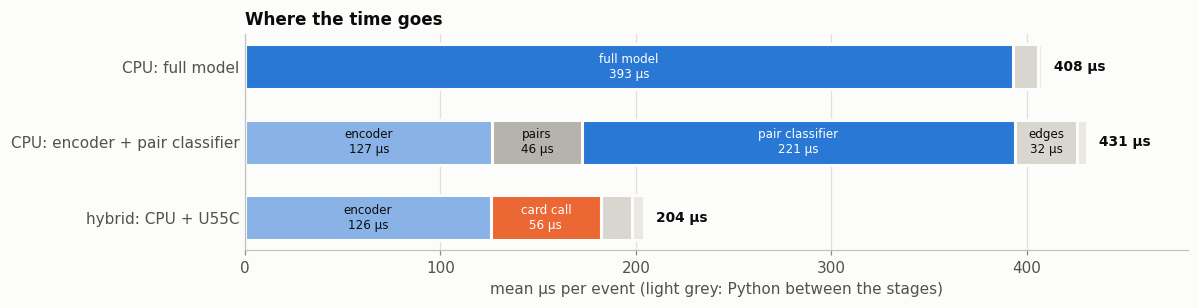

Plot saved as 'work/figures/stages.png'


In [11]:
# Visualize the mean time of each stage (no changes needed)
STAGES = {"full": ["model", "edges"], "split": ["encoder", "pairs", "head", "edges"],
          "card": ["encoder", "card", "edges"]}
plot_stages(timings, total_us, STAGES, save_to=FIGURE_DIR / "stages.png")
print("Plot saved as 'work/figures/stages.png'")

On the CPU split path most of the time goes to the pair classifier; on the hybrid path it shrinks to one card call, and the **encoder**, still on the CPU, becomes the largest part.

### Task 4.3: Anatomy of a Card Call
The driver times every part of a call: the transfer of the embeddings to the card (over PCIe), the kernel, and the transfer of the candidates back. The transfers cost about the same for every event; the kernel time is a few µs to start and stop it, plus the work: 16 clocks per hit for the first layer, and one clock per pair (the dashed line).

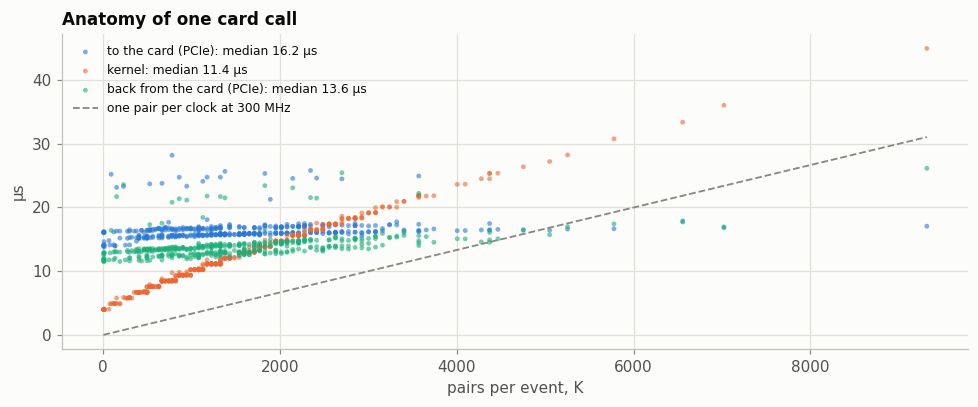

Plot saved as 'work/figures/card_call.png'


In [12]:
# Visualize the parts of a card call (no changes needed)
plot_card_call(timings["card"], pairs_per_event, BITSTREAM["kernel_mhz"], save_to=FIGURE_DIR / "card_call.png")
print("Plot saved as 'work/figures/card_call.png'")

## Part 5: Batching
The fixed costs of a card call (two transfers, start, stop) are paid once per call. If we send B events in one call, each event pays only 1/B of them. The encoder still runs event by event on the CPU; then all the embeddings go to the card together. The catch: each event waits until its batch is complete, so batching suits offline processing better than a strict per-event latency budget.

### Task 5.1: One Call for Several Events

In [13]:
# SOLUTION: send the embeddings of all the events of a batch to the card in one call

def run_batch(batch_events):
    embeddings = [encode(event["hits"]) for event in batch_events]
    rows, logit0, logit1, candidates_per_event = card.run_unpacked(embeddings, CANDIDATE_THRESHOLD, FRACTION_BITS)

    # p1 = softmax(l0, l1)[1] for all the candidates of the batch at once, then the threshold
    largest = np.maximum(logit0, logit1)
    exp0, exp1 = np.exp(logit0 - largest), np.exp(logit1 - largest)
    p1 = exp1 / (exp0 + exp1)
    keep = p1 > np.float32(THRESHOLD)

    # split the candidates back into events
    edges_per_event = []
    end = 0
    for n_candidates in candidates_per_event:
        start, end = end, end + n_candidates
        edges_per_event.append((rows[start:end][keep[start:end]], p1[start:end][keep[start:end]]))
    return edges_per_event

# Check: the edges of one call for 32 events are those of 32 calls of one event
for batched, single in zip(run_batch(events[:32]), edges_of_path["card"][:32]):
    assert np.array_equal(batched[0], single[0]) and np.array_equal(batched[1], single[1])
print("Batched edges == the edges of one call per event")

Batched edges == the edges of one call per event


  1 events per call:  199.7 µs per event


  2 events per call:  171.3 µs per event


  4 events per call:  151.6 µs per event


  8 events per call:  143.5 µs per event
 16 events per call:  135.8 µs per event


 32 events per call:  132.5 µs per event
 64 events per call:  132.4 µs per event


128 events per call:  131.5 µs per event


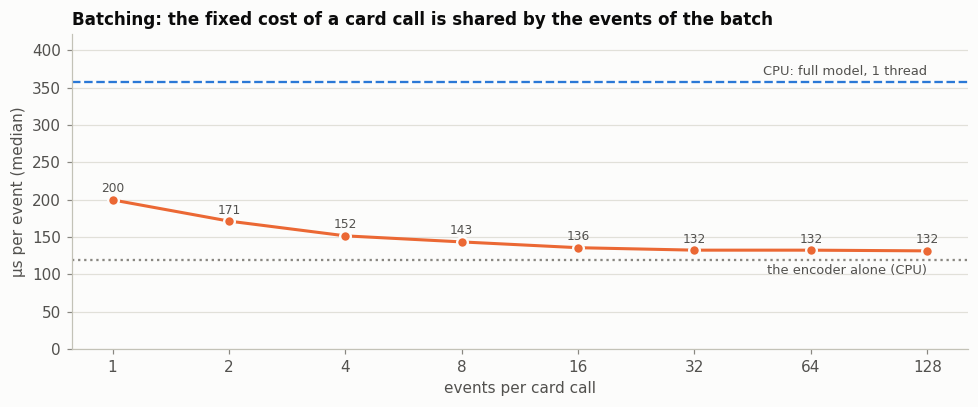

Plot saved as 'work/figures/batching.png'


In [14]:
# Measure the time per event for batches of 1 to 128 events (no changes needed)
batched_us = {}
for batch_size in (1, 2, 4, 8, 16, 32, 64, 128):
    batches = [events[start:start + batch_size] for start in range(0, len(events), batch_size)]
    for batch_events in batches[:2]:                           # warm-up
        run_batch(batch_events)
    us_per_event = []
    for batch_events in batches:
        repeat_us = []
        for _ in range(3):
            start = time.perf_counter_ns()
            run_batch(batch_events)
            repeat_us.append(microseconds(start, time.perf_counter_ns()))
        us_per_event.append(np.median(repeat_us) / len(batch_events))
    batched_us[batch_size] = float(np.median(us_per_event))
    print(f"{batch_size:3d} events per call: {batched_us[batch_size]:6.1f} µs per event")

encoder_median = np.median([times["encoder"] for times in timings["card"]])
plot_batching(batched_us, full_median, encoder_median, save_to=FIGURE_DIR / "batching.png")
print("Plot saved as 'work/figures/batching.png'")

With a few tens of events per call, the time per event gets close to the time of the encoder alone: the fixed costs of the card are almost gone, and the CPU encoder is the next limit.

## Part 6: A Fair Comparison
So far ONNX Runtime used one CPU thread. It can also split each operation over several threads (this machine has 4 cores). A fair comparison uses the best setting of each side: the cell below measures the full model, and the hybrid with its encoder, on 1, 2 and 4 threads (about one minute).

1 thread(s): full model  366.2 µs, hybrid  194.8 µs per event


2 thread(s): full model  322.0 µs, hybrid  192.3 µs per event


4 thread(s): full model  300.2 µs, hybrid  188.5 µs per event


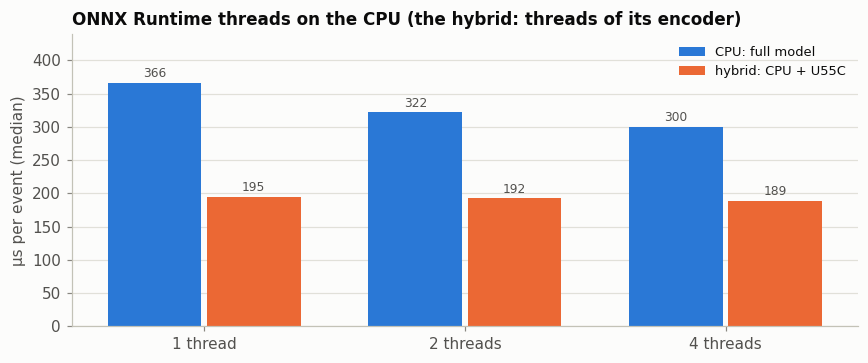

Plot saved as 'work/figures/threads.png'


In [15]:
# Measure the full model and the hybrid with 1, 2 and 4 threads (no changes needed)
THREAD_COUNTS = (1, 2, 4)
cpu_us_by_threads, hybrid_us_by_threads = {}, {}
for n_threads in THREAD_COUNTS:
    threaded_full_session = ort_session(FULL_MODEL, n_threads)
    threaded_encoder_session = ort_session(WORK_DIR / "onnx" / "encoder.onnx", n_threads)

    def run_full_threaded(hits, times):
        probabilities = threaded_full_session.run(None, {"data": hits, "pair_indices": pair_list(len(hits))})[0]
        hi_common.edges_from_probs(probabilities[0, :, 1], THRESHOLD)

    def run_card_threaded(hits, times):
        embeddings = threaded_encoder_session.run(None, {"data": hits})[0][0]
        rows, logit0, logit1, _ = card.run_unpacked([embeddings], CANDIDATE_THRESHOLD, FRACTION_BITS)
        hi_common.edges_from_unpacked(rows, logit0, logit1, THRESHOLD)

    cpu_us_by_threads[n_threads] = float(np.median([t["total"] for t in measure(run_full_threaded, events, 3)]))
    hybrid_us_by_threads[n_threads] = float(np.median([t["total"] for t in measure(run_card_threaded, events, 3)]))
    print(f"{n_threads} thread(s): full model {cpu_us_by_threads[n_threads]:6.1f} µs, "
          f"hybrid {hybrid_us_by_threads[n_threads]:6.1f} µs per event")

BEST_CPU_THREADS = min(cpu_us_by_threads, key=cpu_us_by_threads.get)
BEST_HYBRID_THREADS = min(hybrid_us_by_threads, key=hybrid_us_by_threads.get)
plot_threads(cpu_us_by_threads, hybrid_us_by_threads, save_to=FIGURE_DIR / "threads.png")
print("Plot saved as 'work/figures/threads.png'")

The full model gains from more threads (its large pair computations can be split), the hybrid's small encoder hardly does.

## Summary

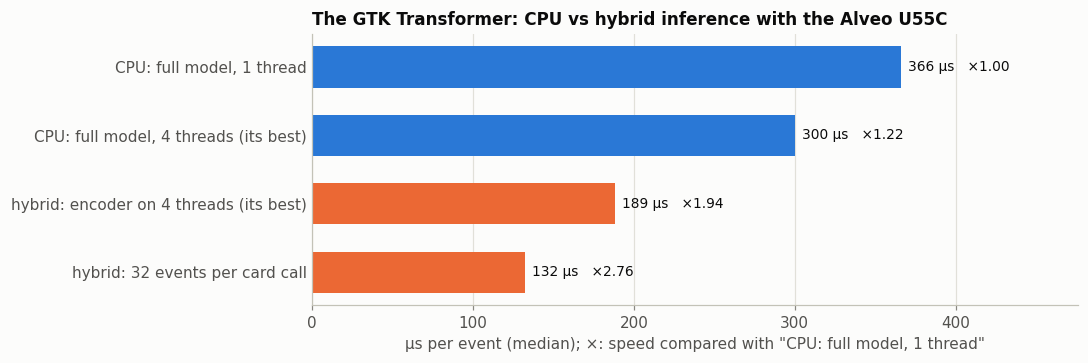

Plot saved as 'work/figures/summary.png'
Best against best: the hybrid is 1.59× faster per event; with 32 events per call, 2.27×


Card released


In [16]:
# The final comparison, and release the card (no changes needed)
def threads_text(n_threads):
    return f"{n_threads} thread{'s' if n_threads > 1 else ''}"


summary = [("CPU: full model, 1 thread", cpu_us_by_threads[1], "full"),
           (f"CPU: full model, {threads_text(BEST_CPU_THREADS)} (its best)", cpu_us_by_threads[BEST_CPU_THREADS], "full"),
           (f"hybrid: encoder on {threads_text(BEST_HYBRID_THREADS)} (its best)",
            hybrid_us_by_threads[BEST_HYBRID_THREADS], "card"),
           ("hybrid: 32 events per card call", batched_us[32], "card")]
plot_summary(summary, save_to=FIGURE_DIR / "summary.png")
print("Plot saved as 'work/figures/summary.png'")
print(f"Best against best: the hybrid is {cpu_us_by_threads[BEST_CPU_THREADS] / hybrid_us_by_threads[BEST_HYBRID_THREADS]:.2f}× "
      f"faster per event; with 32 events per call, {cpu_us_by_threads[BEST_CPU_THREADS] / batched_us[32]:.2f}×")

card.close()
print("Card released")

**What you have done.** You took a Transformer that _hls4ml_ cannot convert as a whole (Exercise 0), split it where it goes from hits to pairs (Exercise 1), turned its pair classifier into fixed-point firmware with _hls4ml_ (Exercise 2), and ran it on the Alveo U55C inside a kernel that builds the pairs on the chip (this exercise).

The hybrid model gives the same results as the float model (bit-exact with its C simulation, the same tracks to within one or two) and is faster than the CPU, even against the CPU's best thread count; batching several events per call makes it faster still. What limits it now is the encoder on the CPU, the next part to move to the FPGA.